In [6]:
#Load libraries 
import pandas as pd
import numpy as np

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

import matplotlib.pyplot as plt

In [7]:
#Load processed data
X_train = pd.read_csv("../Preprocessing/X_train_processed.csv")
X_test = pd.read_csv("../Preprocessing/X_test_processed.csv")

y_train = pd.read_csv("../Preprocessing/y_train_processed.csv").squeeze()
y_test = pd.read_csv("../Preprocessing/y_test_processed.csv").squeeze()

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (36168, 64)
X_test: (9043, 64)
y_train: (36168,)
y_test: (9043,)


In [8]:
#check target
print("Training target values:")
print(y_train.value_counts())

print("\nTesting target values:")
print(y_test.value_counts())

Training target values:
y
no     31937
yes     4231
Name: count, dtype: int64

Testing target values:
y
no     7985
yes    1058
Name: count, dtype: int64


In [9]:
#Convert to binary 
y_train = y_train.map({
    "no": 0,
    "yes": 1
})

y_test = y_test.map({
    "no": 0,
    "yes": 1
})

print("\nConverted target:")
print(y_train.value_counts())


Converted target:
y
0    31937
1     4231
Name: count, dtype: int64


In [10]:
#check missing values
print("Missing values in X_train:", X_train.isnull().sum().sum())
print("Missing values in X_test:", X_test.isnull().sum().sum())
print("Missing values in y_train:", y_train.isnull().sum())
print("Missing values in y_test:", y_test.isnull().sum())

Missing values in X_train: 0
Missing values in X_test: 0
Missing values in y_train: 0
Missing values in y_test: 0


In [11]:
#create logistic regression model
model = LogisticRegression(
    C=1.0,
    solver="liblinear",
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

In [12]:
#train model
model.fit(X_train, y_train)

print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


In [13]:
#generate predictions
y_pred = model.predict(X_test)

y_pred_proba = model.predict_proba(X_test)[:, 1]

print("Predictions generated successfully.")

Predictions generated successfully.


In [14]:
#Accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", round(accuracy, 4))

Accuracy: 0.8458


In [15]:
#precision,recall and F1
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1-score:", round(f1, 4))

Precision: 0.4181
Recall: 0.811
F1-score: 0.5518


In [17]:
#ROC_AUC
roc_auc = roc_auc_score(y_test, y_pred_proba)

print("ROC-AUC:", round(roc_auc, 4))

ROC-AUC: 0.9097


In [18]:
#Classification report
print(classification_report(
    y_test,
    y_pred,
    target_names=["No", "Yes"]
))

              precision    recall  f1-score   support

          No       0.97      0.85      0.91      7985
         Yes       0.42      0.81      0.55      1058

    accuracy                           0.85      9043
   macro avg       0.69      0.83      0.73      9043
weighted avg       0.91      0.85      0.87      9043



In [19]:
#confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[6791 1194]
 [ 200  858]]


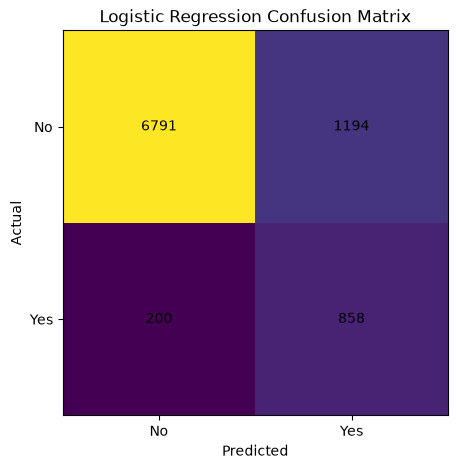

In [20]:
plt.figure(figsize=(6, 5))

plt.imshow(cm)

plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.xticks([0, 1], ["No", "Yes"])
plt.yticks([0, 1], ["No", "Yes"])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.show()

In [21]:
# Store Model 1 evaluation results

model1_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC"
    ],
    "Logistic Regression": [
        accuracy,
        precision,
        recall,
        f1,
        roc_auc
    ]
})

print(model1_results)

      Metric  Logistic Regression
0   Accuracy             0.845848
1  Precision             0.418129
2     Recall             0.810964
3   F1-score             0.551768
4    ROC-AUC             0.909661


In [22]:
# Save results
model1_results.to_csv(
    "model1_results.csv",
    index=False
)

print("\nModel 1 results saved successfully.")


Model 1 results saved successfully.
